In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.svm import SVC

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import(
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)



In [8]:
iris=load_iris()

X=iris.data
Y=iris.target

print(f"Feature Names: {iris.feature_names}")
print(f"target Names: {iris.target_names}")

print(f" shape of dataset :{X.shape}")




Feature Names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
target Names: ['setosa' 'versicolor' 'virginica']
 shape of dataset :(150, 4)


In [11]:
Y_binary=(Y!=0).astype(int)
print(f"Binary Labels :{np.unique(Y_binary,return_counts=True)}")

X2=X[:,[2,3]]

Binary Labels :(array([0, 1]), array([ 50, 100]))


In [14]:
X_train,X_test,Y_train,Y_test=train_test_split(X2,
                                               Y_binary,
                                               test_size=0.2,
                                               random_state=42,
                                               stratify=Y_binary
                                              )

print(f"Training images={X_train.shape[0]}")
print(f"Testing images={X_test.shape[0]}")

Training images=120
Testing images=30


In [15]:
scaler= StandardScaler()

X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [19]:
linear_svm=SVC(
    kernel="linear",
    C=1.0
)

linear_svm.fit(X_train_scaled,Y_train)


,C,1.0
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [20]:
y_pred=linear_svm.predict(X_test_scaled)

acc=accuracy_score(y_pred,Y_test)

print(f"Accuracy : {acc * 100}")

print(f"Classification  Report:\n{classification_report(y_pred,Y_test)}")

Accuracy : 100.0
Classification  Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00        20

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



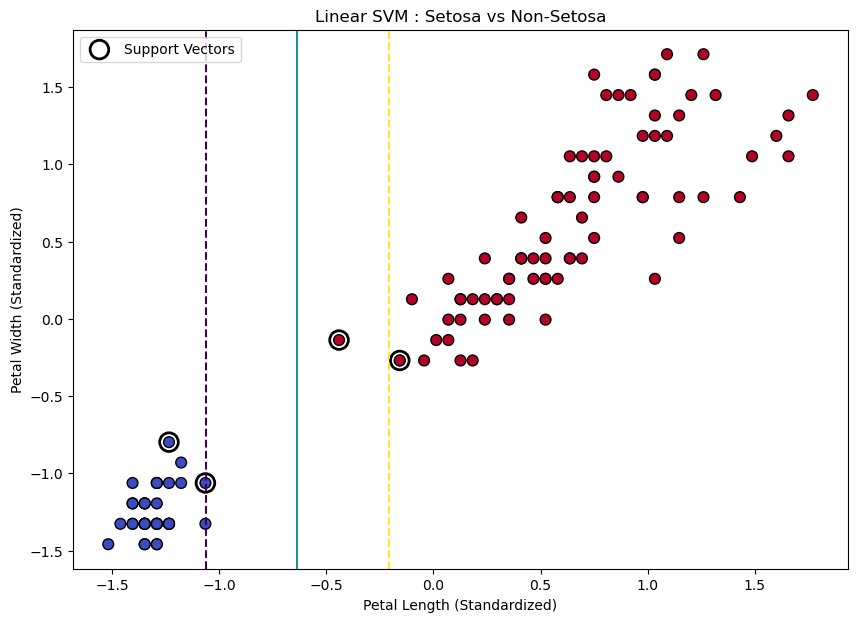

In [54]:
plt.figure(figsize=(10,7))

plt.scatter(
    X_train_scaled[:,0],
    X_train_scaled[:,1],
    c=Y_train,
    s=60,
    cmap='coolwarm',
    edgecolors='k'
)

ax=plt.gca()
xlim=ax.get_xlim()
ylim=ax.get_ylim()

xx=np.linspace(xlim[0],xlim[1],200)
yy=np.linspace(ylim[0],ylim[1],200)
yy,xx=np.meshgrid(yy,xx)

xy=np.vstack([xx.ravel(),xx.ravel()]).T


z=linear_svm.decision_function(xy)
z=z.reshape(xx.shape)

ax.contour(
    xx,
    yy,
    z,
    levels=[-1,0,1],
    linestyles=['--','-','--']
)

ax.scatter(
    linear_svm.support_vectors_[:,0],
    linear_svm.support_vectors_[:,1],
    s=180,
    facecolors='none',
    edgecolors='black',
    linewidths=2,
    label='Support Vectors'
)


plt.xlabel("Petal Length (Standardized)")
plt.ylabel("Petal Width (Standardized)")
plt.title("Linear SVM : Setosa vs Non-Setosa")
plt.legend()
plt.show()


    
    

In [40]:
X_full=iris.data
Y_full=iris.target

X_train_full,X_test_full,Y_train_full,Y_test_full=train_test_split(X_full,
                                               Y_full,
                                               test_size=0.2,
                                               random_state=42,
                                               stratify=Y_full
                                              )


scaler= StandardScaler()

X_train_scaled_full=scaler.fit_transform(X_train_full)
X_test_scaled_full=scaler.transform(X_test_full)



In [42]:
models={
    "Linear": SVC(kernel="linear",C=1.0),
    "Polynomial": SVC(kernel="poly",degree=3,C=1.0),
    "RBF": SVC(kernel="rbf",gamma="scale",C=1.0)
}
results={}
for name,model in models.items():
    model.fit(X_train_scaled_full,Y_train_full)
    y_pred=model.predict(X_test_scaled_full)
    acc=accuracy_score(Y_test_full, y_pred)
    results[name]=acc

    print(f"\n{name} Kernel")
    print("*" *30) 

    print(f"accuracy:{acc}")
    print(f"Classification  Report:\n{classification_report(Y_test_full, y_pred, target_names=iris.target_names)}")
    


Linear Kernel
******************************
accuracy:1.0
Classification  Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30


Polynomial Kernel
******************************
accuracy:0.9
Classification  Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.77      1.00      0.87        10
   virginica       1.00      0.70      0.82        10

    accuracy                           0.90        30
   macro avg       0.92      0.90      0.90        30
weighted avg       0.92      0.90      0.90        30


RBF Kernel
******************************
accuracy:0.96666666666666